# Task 3 Handling missing data

## Imports

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.neighbors import KNeighborsRegressor

## Auxiliary functions

In [15]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    # Only one target variable: SurvivalTime
    label = 'SurvivalTime'
    MAX = 500

    # Select indices for plotting
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    # Plot True vs Predicted for SurvivalTime
    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    # Create a DataFrame with the 'id' column and the predictions
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    # Save the DataFrame to a CSV file
    df.to_csv(path, index=False)
    
def evaluate_model(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Metric': ['Max Error', 'Min Error', 'Mean Error', 'Std of Error'],
        'Value': [
            np.max(np.abs(error)),
            np.min(np.abs(error)),
            np.mean(np.abs(error)),
            np.std(error)
        ]
    }
    return pd.DataFrame(metrics)

## Data preprocessing

In [38]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.head()

,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,SurvivalTime,Censored
0,65.0,0,2,1.0,0,0.0,0.0,4.2,0
1,68.0,1,2,0.0,1,1.0,1.0,4.7,1
2,68.0,1,3,1.0,1,0.0,1.0,3.5,1
3,81.0,1,4,1.0,1,3.0,0.0,2.3,0
4,59.0,1,2,1.0,0,NaN,0.0,NaN,0


In [39]:
# drop unlabeled rows (missing Survival Time)
df = df.dropna(subset=['SurvivalTime'])

print(f"Remaining points after removing unlabeled rows: {df.shape[0]}")

df.head()

Remaining points after removing unlabeled rows: 240


,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,SurvivalTime,Censored
0,65.0,0,2,1.0,0,0.0,0.0,4.2,0
1,68.0,1,2,0.0,1,1.0,1.0,4.7,1
2,68.0,1,3,1.0,1,0.0,1.0,3.5,1
3,81.0,1,4,1.0,1,3.0,0.0,2.3,0
5,47.0,1,4,1.0,1,NaN,0.0,2.6,0


In [40]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (240, 7)
Target vector y shape: (240,)
Censored vector c shape: (240,)


## Task 3.1 Missing data imputation

### Completing missing data

#### Function for evaluating imputation

In [41]:
def evaluate_imputation(X, y, c, regressor=LinearRegression(), method='simple', strategy='mean', n_neighbors=5, show_cmse=True, show_metrics=False, show_plot=False):
    if method == 'simple':
        imputer = SimpleImputer(strategy=strategy)
    elif method == 'knn':
        imputer = KNNImputer(n_neighbors=n_neighbors)
    elif method == 'iterative':
        imputer = IterativeImputer()
        
    X_imp = imputer.fit_transform(X)
    
    # Train-test split
    X_train_imp, X_test_imp, y_train, y_test = train_test_split(X_imp, y, test_size=0.2, random_state=42)
    c_train, c_test = train_test_split(c, test_size=0.2, random_state=42)
    
    model = make_pipeline(StandardScaler(), regressor)
    
    # Cross validation
    y_pred_cv = cross_val_predict(model, X_train_imp, y_train, cv=10)
    cMSE_cv = cMSE(y_train, y_pred_cv, c_train)
    
    model.fit(X_train_imp, y_train)
    
    y_pred_imp = model.predict(X_test_imp)
    cMSE_test = cMSE(y_test, y_pred_imp, c_test)
    
    if show_cmse:
        print(f"CV cMSE: {cMSE_cv}")
        print(f"Test cMSE: {cMSE_test}")
    
    # Evaluate performance
    if show_metrics:
        metrics = evaluate_model(y_test, y_pred_imp)
        print(metrics.T.to_string(index=False, header=False))
    
    if show_plot:
        plot_y_yhat(y_test, y_pred_imp, plot_title="y_yhat_plot")
    
    return model, cMSE_cv

### Evaluating imputation on the baseline

#### Simple imputer

##### Mean

CV cMSE: 2.4907430779190625
Test cMSE: 2.9271810889315084
Max Error Min Error Mean Error Std of Error
 6.085768  0.069093   1.419224     1.801449


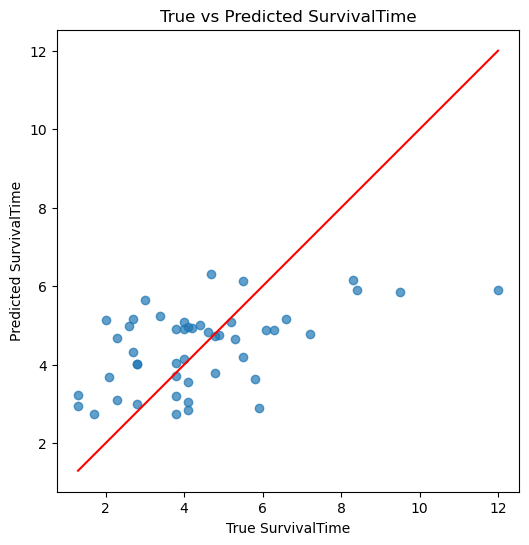

In [42]:
imp_simple_mean_model, imp_simple_mean_cmse = evaluate_imputation(X, y, c, regressor=LinearRegression(), method='simple', strategy='mean', show_metrics=True, show_plot=True)

##### Median

In [21]:
imp_simple_median_model, imp_simple_median_cmse = evaluate_imputation(X, y, c, regressor=LinearRegression(), method='simple', strategy='median', show_plot=False)

CV cMSE: 2.5046377510826243
Test cMSE: 3.0505749153784465


##### Most frequent

In [22]:
imp_simple_most_frequent_model, imp_simple_most_frequent_cmse = evaluate_imputation(X, y, c, regressor=LinearRegression(), method='simple', strategy='most_frequent', show_plot=False)

CV cMSE: 2.5046377510826243
Test cMSE: 3.0505749153784465


##### Median strategy on best model from task 2 (KNN with k=13)

K = 13

In [25]:
imp_simple_mean_model_knn, imp_simple_mean_cmse_knn = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=13), method='simple', strategy='mean')

CV cMSE: 2.6911134738658777
Test cMSE: 3.1455374753451673


Determine best K for KNN regressor

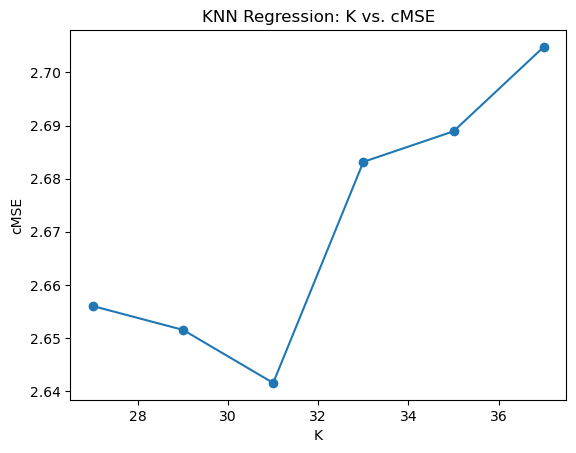

In [23]:
k_values = [27, 29, 31, 33, 35, 37]
knn_scores = []

for k in k_values:
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=k), method='simple', strategy='mean', show_cmse=False, show_plot=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

In Simple imputation by mean, best K for KNN regressor is 31

In [24]:
imp_simple_mean_model_knn, imp_simple_mean_cmse_knn = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=31), method='simple', strategy='mean')

CV cMSE: 2.641534371748179
Test cMSE: 3.1593325095386753


#### KNN imputer

##### Find best K for KNN imputer with cross validation

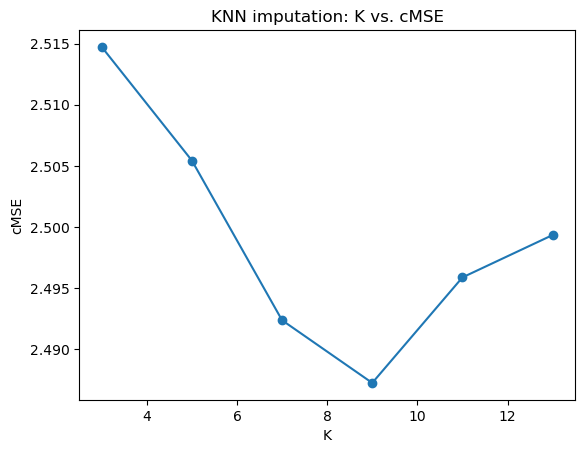

In [26]:
k_values = [3, 5, 7, 9, 11, 13]
knn_scores = []

for k in k_values:
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, regressor=LinearRegression(), method='knn', n_neighbors=k, show_cmse=False, show_plot=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN imputation: K vs. cMSE")
plt.show()

Best K for KNN imputer is 9

In [27]:
imp_knn_model_knn, imp_knn_cmse_knn = evaluate_imputation(X, y, c, regressor=LinearRegression(), method='knn', n_neighbors=9)

CV cMSE: 2.487248963751719
Test cMSE: 2.9790357727957524


##### KNN imputation with k=9 on best model from task 2 (KNN with k=13)

K = 13

In [28]:
imp_knn_model_knn, imp_knn_cmse_knn = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=13), method='knn', n_neighbors=9)

CV cMSE: 2.7029838510848125
Test cMSE: 2.9763387573964493


Determine the best K for the KNN regressor

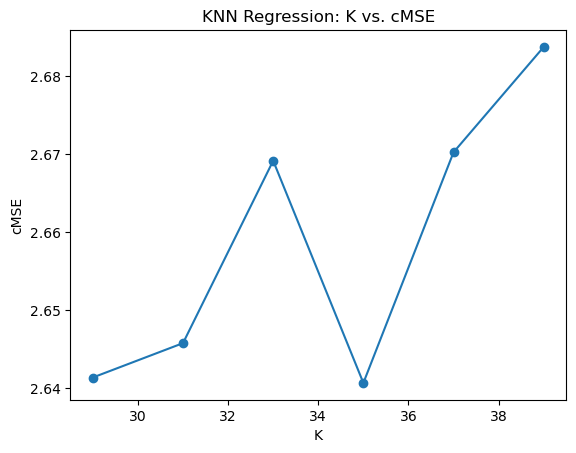

In [29]:
k_values = [29, 31, 33, 35, 37, 39]
knn_scores = []

for k in k_values:
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=k), method='knn', n_neighbors=9, show_cmse=False, show_plot=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

In KNN imputation, best K for KNN regressor is 35

In [30]:
imp_knn_model_knn, imp_knn_cmse_knn = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=35), method='knn', n_neighbors=9)

CV cMSE: 2.640671258503401
Test cMSE: 3.280455952380953


#### Iterative imputer

##### Evaluation

In [31]:
imp_iterative_model, imp_iterative_cmse = evaluate_imputation(X, y, c, regressor=LinearRegression(), method='iterative')

CV cMSE: 2.495061939938149
Test cMSE: 2.9327982762407196


##### Iterative imputation on best model from task 2 (KNN with k = 13)

K = 13

In [32]:
imp_iterative_model_knn, imp_iterative_cmse_knn = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=13), method='iterative')

CV cMSE: 2.656064780571992
Test cMSE: 3.1494489644970414


Determine best K for KNN regressor

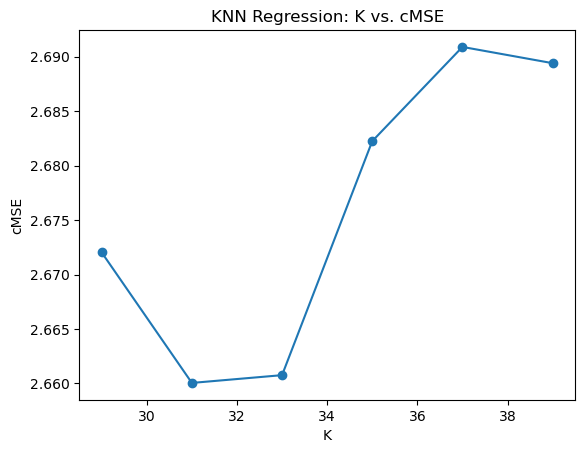

In [33]:
k_values = [29, 31, 33, 35, 37, 39]
knn_scores = []

for k in k_values:
    imp_knn_model, imp_knn_cmse = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=k), method='iterative', show_cmse=False)
    knn_scores.append(imp_knn_cmse)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

In Iterative imputation, best K for KNN regressor is 31

In [37]:
imp_iterative_model_knn, imp_iterative_cmse_knn = evaluate_imputation(X, y, c, regressor=KNeighborsRegressor(n_neighbors=31), method='iterative')

CV cMSE: 2.6600452003121746
Test cMSE: 3.1532021765522025


## Task 3.2 Train models that do not require imputation

## Task 3.3 Evaluation